# Phase 1 — Narration eligibility and audio QC

**Objective:** Create a reproducible first-pass eligibility manifest for Dataset A Narration.

**Rules for this phase:**
- Preserve every source row and its raw transcription.
- Exclude missing or empty references from supervised training.
- Exclude audio that failed full decoding or has zero frames.
- Hold audio with a known duration discrepancy for review.
- Use decoded duration of 0.5–30 seconds for the first Whisper experiment.
- Keep longer and shorter clips in the audit manifest for later decisions.
- Do not change IPA symbols or assign dataset splits here.

The resulting candidate count is **before** speaker/session grouping, duplicate-audio checks, and final train/validation/test splitting.

In [1]:
from pathlib import Path
from datetime import datetime
import hashlib
import json

import pandas as pd

# Find BTP from either BTP/ or BTP/notebooks/.
current = Path.cwd().resolve()
project = next(
    (
        folder for folder in (current, *current.parents)
        if (folder / "manifests" / "master_A_v1_1.parquet").is_file()
        and (folder / "raw" / "A_narration").is_dir()
    ),
    None,
)

if project is None:
    raise FileNotFoundError(
        f"Could not locate the BTP project above {current}"
    )

master_path = project / "manifests" / "master_A_v1_1.parquet"
decode_path = project / "manifests" / "audio_decode_facts_A.parquet"

if not decode_path.is_file():
    raise FileNotFoundError(decode_path)

print("Project:", project)
print("Master:", master_path.relative_to(project))
print("Full-decode facts:", decode_path.relative_to(project))
print("Python environment:", Path(__import__("sys").prefix))

Project: /Users/kanchanpotdar/Downloads/BTP
Master: manifests/master_A_v1_1.parquet
Full-decode facts: manifests/audio_decode_facts_A.parquet
Python environment: /Users/kanchanpotdar/Downloads/BTP/.venv


## 1. Load only the columns required for eligibility

The master supplies raw labels, audio locations, metadata, and earlier audio flags. The separate full-decode audit supplies evidence that the complete waveform was readable. We join them by `sample_id`, never by row position.

In [2]:
master_columns = [
    "sample_id",
    "audio_path",
    "original_audio_id",
    "original_split",
    "transcript_raw",
    "transcript_missing",
    "duration_seconds",
    "duration_decoded",
    "length_matches_stated",
    "audio_ok",
    "audio_issue",
    "audio_sr",
    "audio_channels",
    "speaker_id",
    "speaker_id_raw",
    "speaker_status",
    "speaker_group_id",
    "recording_session_id",
    "is_pair_recording",
    "train_only",
    "group_train_only",
    "sentence_id",
    "boundary_id",
]

decode_columns = [
    "sample_id",
    "full_decode_success",
    "decoded_frames",
    "sample_rate",
    "channels",
    "duration_exact",
    "error",
]

master = pd.read_parquet(master_path, columns=master_columns)
decode = pd.read_parquet(decode_path, columns=decode_columns)

# Reject duplicated IDs before joining; otherwise a merge could inflate counts.
if master["sample_id"].isna().any() or master["sample_id"].duplicated().any():
    raise ValueError("Master contains missing or duplicate sample_id values.")

if decode["sample_id"].isna().any() or decode["sample_id"].duplicated().any():
    raise ValueError("Decode facts contain missing or duplicate sample_id values.")

audit = master.merge(
    decode,
    on="sample_id",
    how="left",
    validate="one_to_one",
    indicator=True,
)

print("Master rows:", len(master))
print("Full-decode fact rows:", len(decode))
print("Joined rows:", len(audit))
print("Join results:", audit["_merge"].value_counts().to_dict())

if not audit["_merge"].eq("both").all():
    raise ValueError("Some master samples lack full-decode facts.")

audit = audit.drop(columns="_merge")


Master rows: 6718
Full-decode fact rows: 6718
Joined rows: 6718
Join results: {'both': 6718, 'left_only': 0, 'right_only': 0}


In [3]:
# These checks flag unexpected metadata. They do not rewrite any audio.
sample_rate_mismatch = audit["audio_sr"].ne(audit["sample_rate"])
channel_mismatch = audit["audio_channels"].ne(audit["channels"])

decoded_difference = (
    audit["duration_decoded"] - audit["duration_exact"]
).abs()
decoded_duration_mismatch = decoded_difference.gt(0.001)

print("Sample-rate disagreements:", int(sample_rate_mismatch.sum()))
print("Channel-count disagreements:", int(channel_mismatch.sum()))
print("Decoded-duration disagreements over 1 ms:",
      int(decoded_duration_mismatch.sum()))
print("Full-decode failures:",
      int((~audit["full_decode_success"].fillna(False)).sum()))
print("Zero-frame recordings:",
      int(audit["decoded_frames"].eq(0).sum()))

unexpected = (
    sample_rate_mismatch
    | channel_mismatch
    | decoded_duration_mismatch
)

if unexpected.any():
    print("\nRows requiring investigation:")
    print(
        audit.loc[
            unexpected,
            ["sample_id", "audio_sr", "sample_rate",
             "audio_channels", "channels",
             "duration_decoded", "duration_exact"]
        ].to_string(index=False)
    )

Sample-rate disagreements: 0
Channel-count disagreements: 0
Decoded-duration disagreements over 1 ms: 0
Full-decode failures: 0
Zero-frame recordings: 3


## 2. Apply explicit first-pass eligibility rules

Every row receives a reason. A row with multiple problems receives the **first applicable reason** in the order below; the separate boolean flags retain all applicable problems. This lets us make a filtering waterfall without double-counting excluded rows.

The duration discrepancy is a *review hold*, not a claim that the waveform is corrupt. Clips over 30 seconds remain available for later aligned segmentation.

In [4]:
# A literal "N/A" is used as a missing-reference marker in this dataset.
# The supplied transcript_missing flag is the primary indication of that state.
raw_text = audit["transcript_raw"].astype("string")
nonempty_text = raw_text.str.strip().fillna("").ne("")
reference_present = (
    ~audit["transcript_missing"].fillna(True).astype(bool)
) & nonempty_text

decode_succeeded = audit["full_decode_success"].fillna(False).astype(bool)
has_frames = audit["decoded_frames"].fillna(0).gt(0)

# The earlier audio_ok flag also marks the one known duration discrepancy.
# Treat it as a review hold, while keeping its exact audio_issue visible.
audio_flag_ok = audit["audio_ok"].fillna(False).astype(bool)
duration_known = audit["duration_decoded"].notna()
duration_in_range = audit["duration_decoded"].between(
    0.5, 30.0, inclusive="both"
)

format_ok = (
    audit["audio_sr"].eq(16_000)
    & audit["audio_channels"].eq(1)
    & audit["sample_rate"].eq(16_000)
    & audit["channels"].eq(1)
)

audit["reference_present"] = reference_present
audit["decode_succeeded"] = decode_succeeded
audit["has_audio_frames"] = has_frames
audit["audio_flag_ok"] = audio_flag_ok
audit["duration_known"] = duration_known
audit["duration_in_0_5_to_30_s"] = duration_in_range
audit["format_16k_mono"] = format_ok

# Keep these individual flags. A later review can revisit one rule without
# having to reconstruct why a sample was originally excluded.
rules = [
    ("missing_or_empty_reference", reference_present),
    ("full_decode_failed", decode_succeeded),
    ("zero_audio_frames", has_frames),
    ("audio_issue_review_hold", audio_flag_ok),
    ("missing_decoded_duration", duration_known),
    ("outside_initial_duration_range", duration_in_range),
    ("unexpected_audio_format", format_ok),
]

remaining = pd.Series(True, index=audit.index)
reason = pd.Series("eligible", index=audit.index, dtype="string")

for exclusion_name, passes_rule in rules:
    passes_rule = passes_rule.fillna(False).astype(bool)
    newly_excluded = remaining & ~passes_rule
    reason.loc[newly_excluded] = exclusion_name
    remaining &= passes_rule

audit["phase1_reason"] = reason
audit["phase1_candidate"] = remaining

print(audit["phase1_reason"].value_counts().to_string())
print("\nFirst-pass candidate rows:", int(audit["phase1_candidate"].sum()))

phase1_reason
eligible                          5086
missing_or_empty_reference        1067
outside_initial_duration_range     561
zero_audio_frames                    3
audio_issue_review_hold              1

First-pass candidate rows: 5086


In [5]:
# Hours are calculated from decoded duration, not the original stated duration.
# This table counts rows remaining after each rule, so exclusions do not overlap.
def hours_of(mask):
    seconds = pd.to_numeric(
        audit.loc[mask, "duration_decoded"], errors="coerce"
    ).fillna(0)
    return float(seconds.sum() / 3600)

waterfall = []
remaining_for_table = pd.Series(True, index=audit.index)

waterfall.append({
    "step": "all master rows",
    "rows_remaining": int(remaining_for_table.sum()),
    "decoded_hours_remaining": hours_of(remaining_for_table),
})

for exclusion_name, passes_rule in rules:
    before = int(remaining_for_table.sum())
    remaining_for_table &= passes_rule.fillna(False).astype(bool)
    after = int(remaining_for_table.sum())

    waterfall.append({
        "step": f"after {exclusion_name}",
        "rows_excluded_at_step": before - after,
        "rows_remaining": after,
        "decoded_hours_remaining": hours_of(remaining_for_table),
    })

waterfall_df = pd.DataFrame(waterfall)
display(waterfall_df)

assert remaining_for_table.equals(audit["phase1_candidate"])

,step,rows_remaining,decoded_hours_remaining,rows_excluded_at_step
0,all master rows,6718,25.792172,NaN
1,after missing_or_empty_reference,5651,20.877134,1067.0
2,after full_decode_failed,5651,20.877134,0.0
3,after zero_audio_frames,5648,20.877134,3.0
4,after audio_issue_review_hold,5647,20.876431,1.0
5,after missing_decoded_duration,5647,20.876431,0.0
6,after outside_initial_duration_range,5086,14.825519,561.0
7,after unexpected_audio_format,5086,14.825519,0.0


In [6]:
# Review examples without printing transcripts or bulk audio into the notebook.
print("Audio-issue review items:")
display(
    audit.loc[
        audit["audio_issue"].fillna("").ne(""),
        [
            "sample_id", "audio_issue", "duration_seconds",
            "duration_decoded", "decoded_frames",
            "transcript_missing", "phase1_reason"
        ],
    ]
)

print(
    "Labelled clips longer than 30 seconds:",
    int((reference_present & audit["duration_decoded"].gt(30)).sum())
)
print(
    "Labelled clips shorter than 0.5 seconds:",
    int((reference_present & audit["duration_decoded"].lt(0.5)).sum())
)
print(
    "Rows with a missing/empty reference:",
    int((~reference_present).sum())
)

Audio-issue review items:


,sample_id,audio_issue,duration_seconds,duration_decoded,decoded_frames,transcript_missing,phase1_reason
4971,A_004972,length_differs_from_stated,3.89,2.531,40496,False,audio_issue_review_hold
4972,A_004973,empty_audio,0.82,0.000,0,False,zero_audio_frames
6613,A_006614,empty_audio,10.97,0.000,0,False,zero_audio_frames
6614,A_006615,empty_audio,10.92,0.000,0,False,zero_audio_frames


Labelled clips longer than 30 seconds: 528
Labelled clips shorter than 0.5 seconds: 36
Rows with a missing/empty reference: 1067


## 3. Save versioned local Phase 1 outputs

The full audit keeps every source row and every eligibility flag. The candidate manifest contains only rows passing the first-pass rules. These are local research outputs containing transcript and speaker metadata; do not upload them to the source-only GitHub repository.

A timestamp prevents this notebook from silently overwriting an earlier Phase 1 run.

In [7]:
def sha256_file(path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        while block := handle.read(chunk_size):
            digest.update(block)
    return digest.hexdigest()

master_sha256_before = sha256_file(master_path)
decode_sha256_before = sha256_file(decode_path)

run_id = datetime.now().astimezone().strftime("%Y%m%d_%H%M%S")
output_dir = project / "outputs" / f"phase1_{run_id}"

# Refuse to reuse an existing directory, preserving earlier decisions and runs.
output_dir.mkdir(parents=True, exist_ok=False)

audit_path = output_dir / "phase1_all_rows.parquet"
candidate_path = output_dir / "phase1_candidates.parquet"
waterfall_path = output_dir / "filtering_waterfall.csv"
summary_path = output_dir / "summary.json"

audit.to_parquet(audit_path, index=False)
audit.loc[audit["phase1_candidate"]].to_parquet(
    candidate_path, index=False
)
waterfall_df.to_csv(waterfall_path, index=False)

summary = {
    "phase": 1,
    "status": "first_pass_completed_pending_review",
    "created_at": datetime.now().astimezone().isoformat(timespec="seconds"),
    "source_master": str(master_path.relative_to(project)),
    "source_master_sha256": master_sha256_before,
    "decode_facts": str(decode_path.relative_to(project)),
    "decode_facts_sha256": decode_sha256_before,
    "master_rows": int(len(audit)),
    "candidate_rows_before_splits": int(audit["phase1_candidate"].sum()),
    "candidate_decoded_hours_before_splits": hours_of(
        audit["phase1_candidate"]
    ),
    "reason_counts": {
        str(key): int(value)
        for key, value in audit["phase1_reason"].value_counts().items()
    },
    "audio_issue_rows": int(audit["audio_issue"].fillna("").ne("").sum()),
    "notes": [
        "All source rows retained in the Phase 1 audit.",
        "No transcript normalization or linguistic substitutions performed.",
        "No duplicate-audio grouping or train/validation/test split performed.",
        "The duration-mismatch row is held for review.",
    ],
}

summary_path.write_text(
    json.dumps(summary, indent=2, ensure_ascii=False) + "\n",
    encoding="utf-8",
)

# Recheck source hashes to confirm this notebook did not change its inputs.
assert sha256_file(master_path) == master_sha256_before
assert sha256_file(decode_path) == decode_sha256_before

print("Saved local outputs in:", output_dir)
print("All-row audit:", audit_path.name)
print("Candidate manifest:", candidate_path.name)
print("Waterfall:", waterfall_path.name)
print("Summary:", summary_path.name)
print(
    "Candidates:",
    summary["candidate_rows_before_splits"],
    f"({summary['candidate_decoded_hours_before_splits']:.3f} decoded hours)",
)
print("Source master and full-decode facts: hashes unchanged")

Saved local outputs in: /Users/kanchanpotdar/Downloads/BTP/outputs/phase1_20261031_202929
All-row audit: phase1_all_rows.parquet
Candidate manifest: phase1_candidates.parquet
Waterfall: filtering_waterfall.csv
Summary: summary.json
Candidates: 5086 (14.826 decoded hours)
Source master and full-decode facts: hashes unchanged


## Visual review of the Narration inventory

These charts show how the Phase 0 inventory changes under Phase 1's
first-pass eligibility rules. They describe the dataset before speaker
grouping and train/validation/test splitting.

Counts and durations come from the saved Phase 1 audit. No transcript,
audio, or individual speaker identifier is displayed.



In [8]:
# Run once if Matplotlib is not already installed in the selected BTP kernel:
%pip install matplotlib

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Use the specific completed Phase 1 run, so plots cannot silently switch
# to a different run if another output directory is created later.
project = Path("/Users/kanchanpotdar/Downloads/BTP")
phase1_dir = project / "outputs" / "phase1_20261031_202929"

audit_plot = pd.read_parquet(phase1_dir / "phase1_all_rows.parquet")
waterfall_plot = pd.read_csv(phase1_dir / "filtering_waterfall.csv")
candidates_plot = audit_plot.loc[audit_plot["phase1_candidate"]].copy()

print("Audit rows:", len(audit_plot))
print("Candidate rows:", len(candidates_plot))
print(
    "Candidate decoded hours:",
    round(candidates_plot["duration_decoded"].sum() / 3600, 3),
)

assert len(audit_plot) == 6718
assert len(candidates_plot) == 5086

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 752.5 kB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 270.1/270.1 kB 607.9 kB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 736.5 kB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.1/64.1 kB 528.6 kB/s eta 0:00:00a 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 443.0 kB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.4/126.4 kB 424.9 kB/s eta 0:00:00a 0:00:01

[notice] A new release of pip available: 22.3.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


Matplotlib is building the font cache; this may take a moment.


Audit rows: 6718
Candidate rows: 5086
Candidate decoded hours: 14.826


### Plot 1 — Where rows leave the first experiment

Each bar shows a mutually exclusive first reason for not entering the
initial Whisper candidate pool. “Outside duration” includes short and
long clips; the next plot separates them.

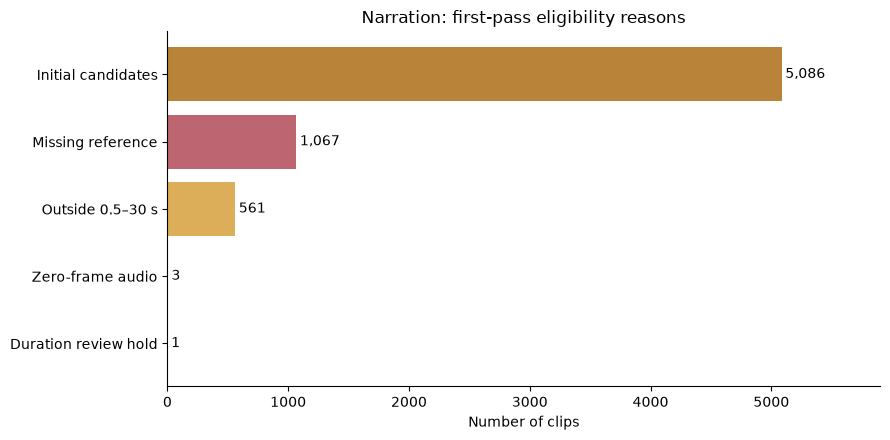

In [9]:
reason_counts = audit_plot["phase1_reason"].value_counts()

labels = {
    "eligible": "Initial candidates",
    "missing_or_empty_reference": "Missing reference",
    "outside_initial_duration_range": "Outside 0.5–30 s",
    "zero_audio_frames": "Zero-frame audio",
    "audio_issue_review_hold": "Duration review hold",
}

ordered = [
    "eligible",
    "missing_or_empty_reference",
    "outside_initial_duration_range",
    "zero_audio_frames",
    "audio_issue_review_hold",
]

values = [int(reason_counts.get(reason, 0)) for reason in ordered]
names = [labels[reason] for reason in ordered]

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(
    names[::-1],
    values[::-1],
    color=["#b98339", "#bd6671", "#ddae5a", "#777fa5", "#328f80"][::-1],
)

for bar in bars:
    value = bar.get_width()
    ax.text(value + 30, bar.get_y() + bar.get_height() / 2,
            f"{int(value):,}", va="center")

ax.set_xlim(0, max(values) * 1.16)
ax.set_xlabel("Number of clips")
ax.set_title("Narration: first-pass eligibility reasons")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### Plot 2 — How long are the labelled recordings?

The 30-second line is Whisper's usual input window for this initial
recipe. Clips beyond it remain in the master for possible later
alignment-aware segmentation.

In [ ]:
labelled = audit_plot.loc[
    audit_plot["reference_present"] & audit_plot["duration_decoded"].gt(0),
    "duration_decoded",
]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(labelled.clip(upper=30), bins=30, color="#4c78a8", edgecolor="white")
axes[0].set_title("Labelled clips: first 30 seconds")
axes[0].set_xlabel("Decoded duration (s; values >30 capped at 30)")
axes[0].set_ylabel("Number of clips")
axes[1].hist(labelled, bins=[0, 0.5, 5, 10, 15, 20, 25, 30, 45, 60, 90, 120, 180],
             color="#38a18a", edgecolor="white")
axes[1].axvline(30, color="#a43d4c", linestyle="--", label="30 s")
axes[1].set_title("Labelled clips: full duration range")
axes[1].set_xlabel("Decoded duration (s)")
axes[1].set_ylabel("Number of clips")
axes[1].legend()
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()
print("Labelled clips over 30 seconds:", int(labelled.gt(30).sum()))
print("Labelled clips under 0.5 seconds:", int(labelled.lt(0.5).sum()))

### Plot 3 — How evenly is candidate audio distributed across speakers?

Speaker identifiers are hidden in the chart. The bars rank public
speaker IDs by candidate audio hours. Public IDs and proposed speaker
groups still need review before any split is frozen.

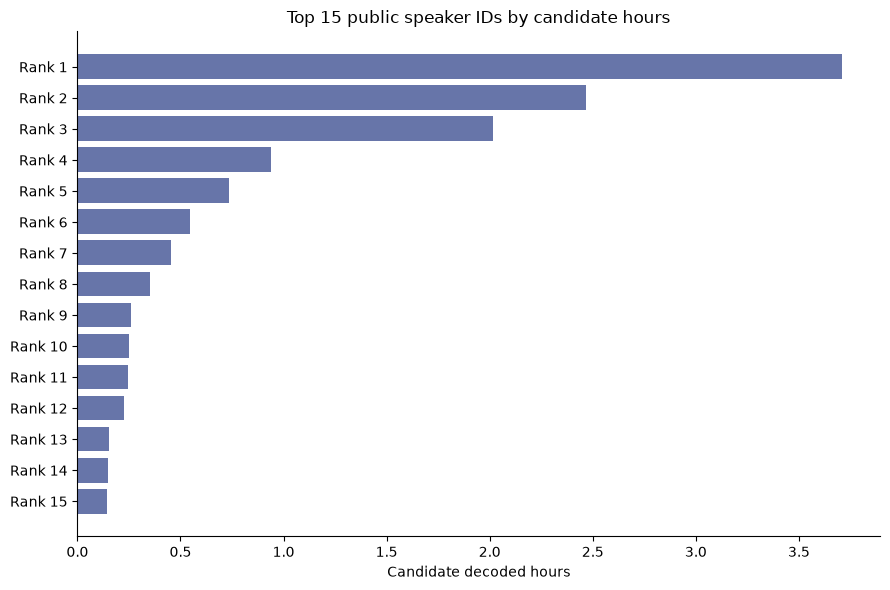

Distinct candidate public speaker IDs: 49
Share of candidate hours from top three public IDs: 55.2%


In [11]:
speaker_hours = (
    candidates_plot
    .groupby("speaker_id", dropna=False)["duration_decoded"]
    .sum()
    .div(3600)
    .sort_values(ascending=False)
)

top_n = 15
top_hours = speaker_hours.head(top_n)
anonymous_labels = [f"Rank {i}" for i in range(1, len(top_hours) + 1)]

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(
    anonymous_labels[::-1],
    top_hours.to_numpy()[::-1],
    color="#6775a9",
)
ax.set_xlabel("Candidate decoded hours")
ax.set_title(f"Top {len(top_hours)} public speaker IDs by candidate hours")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

print("Distinct candidate public speaker IDs:", speaker_hours.size)
print(
    "Share of candidate hours from top three public IDs:",
    f"{top_hours.head(3).sum() / speaker_hours.sum():.1%}",
)

### Plot 4 — Which candidate clips are restricted to training?

The first-pass candidate pool includes speaker records that should not
automatically enter validation or test. The status chart explains why
the 5,086 candidates cannot yet be treated as a finished split.

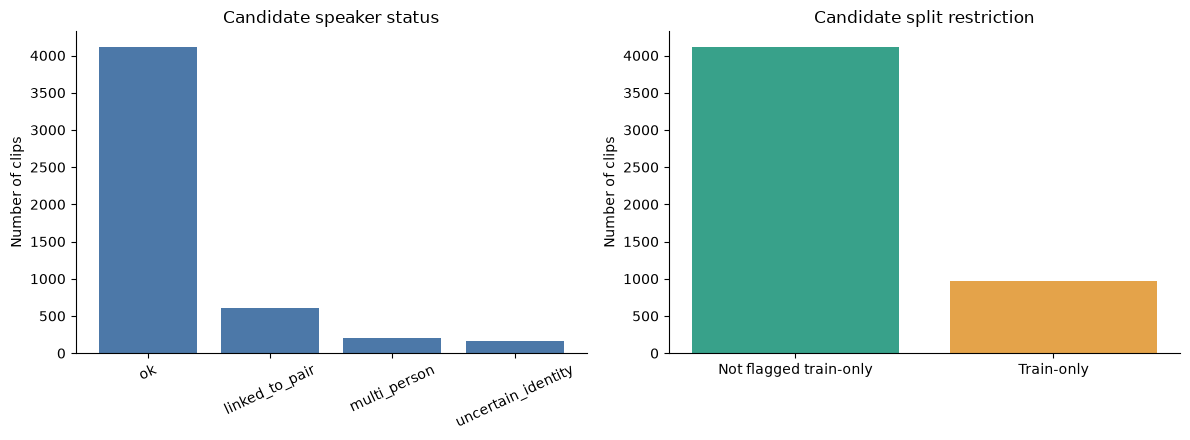

Train-only candidates: 967


In [12]:
status_counts = candidates_plot["speaker_status"].value_counts(dropna=False)
train_only_counts = (
    candidates_plot["train_only"]
    .fillna(False)
    .astype(bool)
    .value_counts()
    .reindex([False, True], fill_value=0)
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].bar(
    status_counts.index.astype(str),
    status_counts.to_numpy(),
    color="#4c78a8",
)
axes[0].set_title("Candidate speaker status")
axes[0].set_ylabel("Number of clips")
axes[0].tick_params(axis="x", rotation=25)

axes[1].bar(
    ["Not flagged train-only", "Train-only"],
    train_only_counts.to_numpy(),
    color=["#38a18a", "#e4a34a"],
)
axes[1].set_title("Candidate split restriction")
axes[1].set_ylabel("Number of clips")

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

print("Train-only candidates:", int(train_only_counts.loc[True]))

## Phase 1 conclusion

- The 6,718 Narration master rows joined one-to-one with the full-decode
  audit. No full-decode failures or sample-rate/channel disagreements
  were found.
- Of 6,718 rows, 1,067 lack a usable reference, three labelled rows
  have zero audio frames, and one labelled row is held for duration review.
- After the initial 0.5–30-second duration rule, 5,086 clips and
  approximately 14.826 decoded hours remain as **first-pass candidates**.
  This is not the final training size.
- The initial duration rule excludes 528 labelled clips over 30 seconds
  and 33 labelled, nonempty clips under 0.5 seconds. Long recordings remain
  available for later aligned segmentation.
- Of the candidates, 967 are marked train-only. Speaker identity proposals
  and recording sessions still need review before held-out splits.
- The master and full-decode files were unchanged. All source rows and
  reasons are retained in the saved Phase 1 audit.

**Phase 1 status:** First-pass eligibility complete; review items remain.